In [ ]:
!pip install sentence-transformers

In [ ]:
!unzip "Datos Mental Risk challenge.zip"

Archive:  Datos Mental Risk challenge.zip
replace MentalRiskEs2023/corpus.zip? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: MentalRiskEs2023/corpus.zip  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject1.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject10.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject100.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject101.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject102.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject103.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject104.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject105.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject106.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject107.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject108.json  
  inflating: MentalRiskEs2023/corpus/Ansiedad/Test/subject109.json  
  inflating: 

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import os
import glob
import json
import pandas as pd

base_path = 'MentalRiskEs2023/corpus'
json_files = glob.glob(os.path.join(base_path, '**/*.json'), recursive=True)

data_list = []

for file_path in json_files:
    parts = os.path.normpath(file_path).split(os.sep)
    if len(parts) >= 5:
        trastorno = parts[-3]
        dataset_type = parts[-2]
        subject_id = os.path.splitext(parts[-1])[0]

        try:
            with open(file_path, 'r', encoding='utf-8') as f:
                content = json.load(f)

                if isinstance(content, list):
                    for message in content:
                        message_data = {
                            'subject_id': subject_id,
                            'trastorno': trastorno,
                            'dataset_type': dataset_type
                        }
                        if isinstance(message, dict):
                            message_data.update(message)
                        else:
                            message_data['message_content'] = message
                        data_list.append(message_data)
                else:
                    content['subject_id'] = subject_id
                    content['trastorno'] = trastorno
                    content['dataset_type'] = dataset_type
                    data_list.append(content)
        except Exception as e:
            print(f"Error: {file_path} - {e}")

df_mental_risk = pd.DataFrame(data_list)

print(f"Total: {len(df_mental_risk)}")
if not df_mental_risk.empty:
    display(df_mental_risk.head())
    print(df_mental_risk.groupby(['trastorno', 'dataset_type']).size())

Total: 28085


,subject_id,trastorno,dataset_type,id_message,message,date
0,subject1,Depresi├а┬╕n,Trial,52166590785,Bien ... técnicamente debería irme a dormir ca...,2021-07-23 11:13:05
1,subject1,Depresi├а┬╕n,Trial,65597414909,jajaj mañana será cara sonriendo con sudor frí...,2021-07-23 11:15:32
2,subject1,Depresi├а┬╕n,Trial,93768794069,"A ver todos hemos mentido una vez , pero hay m...",2021-07-24 02:43:29
3,subject1,Depresi├а┬╕n,Trial,72050945752,Si t soy sincera lo que vi fue la conversación...,2021-07-24 02:47:56
4,subject1,Depresi├а┬╕n,Trial,96156531586,Aki en telegram como en cualquier otra red don...,2021-07-24 02:51:19


trastorno     dataset_type
Ansiedad      Test            5520
Depresi├а┬╕n  Test            5194
              Train           6248
              Trial            624
TCA           Test            4179
              Train           5931
              Trial            389
dtype: int64


In [ ]:
df_train = df_mental_risk[df_mental_risk['dataset_type'] == 'Train'].copy()
df_test = df_mental_risk[df_mental_risk['dataset_type'] == 'Test'].copy()
df_trial = df_mental_risk[df_mental_risk['dataset_type'] == 'Trial'].copy()

for df in [df_train, df_test, df_trial, df_mental_risk]:
    df['trastorno'] = df['trastorno'].apply(lambda x: 'Depresion' if 'Depres' in str(x) else x)

df_train_ansiedad = df_train[df_train['trastorno'] == 'Ansiedad'].copy()
df_train_depresion = df_train[df_train['trastorno'] == 'Depresion'].copy()
df_train_tca = df_train[df_train['trastorno'] == 'TCA'].copy()

print("=== CONJUNTOS DE DATOS PRINCIPALES ===")
print(f"Train DataFrame: {df_train.shape}")
print(f"Test DataFrame:  {df_test.shape}")
print(f"Trial DataFrame: {df_trial.shape}\n")

print("=== SUBDIVISIONES DE TRAIN ===")
print(f"Train - Ansiedad:  {df_train_ansiedad.shape}")
print(f"Train - Depresión: {df_train_depresion.shape}")
print(f"Train - TCA:       {df_train_tca.shape}")

# Vista previa rápida de Train
display(df_train.head())

=== CONJUNTOS DE DATOS PRINCIPALES ===
Train DataFrame: (12179, 6)
Test DataFrame:  (14893, 6)
Trial DataFrame: (1013, 6)

=== SUBDIVISIONES DE TRAIN ===
Train - Ansiedad:  (0, 6)
Train - Depresión: (6248, 6)
Train - TCA:       (5931, 6)


,subject_id,trastorno,dataset_type,id_message,message,date
5818,subject137,Depresion,Train,98731074100,Soy nueva cara feliz con ojos sonrientes,2021-10-11 17:11:53
5819,subject137,Depresion,Train,31137391358,Hace dos días que he salido del área de psiqui...,2021-10-11 17:12:44
5820,subject137,Depresion,Train,64184157842,"Sí , me han puesto tratamiento , pero apenas m...",2021-10-11 17:17:24
5821,subject137,Depresion,Train,83956093570,Muchas gracias a tod @s ...,2021-10-11 18:02:25
5822,subject137,Depresion,Train,79184076811,Buenas noches gente ... estoy volviendo a caer...,2021-10-11 21:29:37


In [ ]:
# 1. Subdivisiones para el conjunto de TRAIN
df_train_ansiedad = df_train[df_train['trastorno'] == 'Ansiedad'].copy()
df_train_depresion = df_train[df_train['trastorno'] == 'Depresion'].copy()
df_train_tca = df_train[df_train['trastorno'] == 'TCA'].copy()

# 2. Subdivisiones para el conjunto de TEST
df_test_ansiedad = df_test[df_test['trastorno'] == 'Ansiedad'].copy()
df_test_depresion = df_test[df_test['trastorno'] == 'Depresion'].copy()
df_test_tca = df_test[df_test['trastorno'] == 'TCA'].copy()

# 3. Subdivisiones para el conjunto de TRIAL
df_trial_ansiedad = df_trial[df_trial['trastorno'] == 'Ansiedad'].copy()
df_trial_depresion = df_trial[df_trial['trastorno'] == 'Depresion'].copy()
df_trial_tca = df_trial[df_trial['trastorno'] == 'TCA'].copy()

# Mostramos las dimensiones de absolutamente todas las particiones
print("=== SUBDIVISIONES COMPLETAS DE LOS DATASETS ===\n")
print(f"TRAIN:")
print(f"  - Ansiedad:  {df_train_ansiedad.shape[0]} registros")
print(f"  - Depresión: {df_train_depresion.shape[0]} registros")
print(f"  - TCA:       {df_train_tca.shape[0]}  registros\n")

print(f"TEST:")
print(f"  - Ansiedad:  {df_test_ansiedad.shape[0]} registros")
print(f"  - Depresión: {df_test_depresion.shape[0]} registros")
print(f"  - TCA:       {df_test_tca.shape[0]}  registros\n")

print(f"TRIAL:")
print(f"  - Ansiedad:  {df_trial_ansiedad.shape[0]}  registros")
print(f"  - Depresión: {df_trial_depresion.shape[0]} registros")
print(f"  - TCA:       {df_trial_tca.shape[0]}  registros")

=== SUBDIVISIONES COMPLETAS DE LOS DATASETS ===

TRAIN:
  - Ansiedad:  0 registros
  - Depresión: 6248 registros
  - TCA:       5931  registros

TEST:
  - Ansiedad:  5520 registros
  - Depresión: 5194 registros
  - TCA:       4179  registros

TRIAL:
  - Ansiedad:  0  registros
  - Depresión: 624 registros
  - TCA:       389  registros


In [ ]:
df_test_ansiedad.head()

,subject_id,trastorno,dataset_type,id_message,message,date
22565,subject137,Ansiedad,Test,50901340741,dorso de mano con índice a la derecha dorso de...,2020-12-10 22:22:13
22566,subject137,Ansiedad,Test,57278767418,Hola : ' 3 ¿ Podría contar lo que me está suce...,2020-12-10 22:33:17
22567,subject137,Ansiedad,Test,4657544686,Bueno lo que me sucede empezó luego de un dolo...,2020-12-10 22:33:50
22568,subject137,Ansiedad,Test,24013868541,Creí que era los ganglios ( aún lo creo ) y bi...,2020-12-10 22:35:15
22569,subject137,Ansiedad,Test,42761482465,Hace un momento creía resolver mi preocupación...,2020-12-10 22:37:36


In [ ]:
df_test_ansiedad.describe()

,id_message
count,5.520000e+03
mean,5.056804e+10
std,2.895114e+10
min,7.321163e+06
25%,2.557572e+10
50%,5.166045e+10
75%,7.560185e+10
max,9.999508e+10


In [ ]:
df.message

,message
0,Bien ... técnicamente debería irme a dormir ca...
1,jajaj mañana será cara sonriendo con sudor frí...
2,"A ver todos hemos mentido una vez , pero hay m..."
3,Si t soy sincera lo que vi fue la conversación...
4,Aki en telegram como en cualquier otra red don...
...,...
28080,Parece mi misma historia enserio cara llorando...
28081,Ahora mismo estoy en la cama todo tal cual lo ...
28082,Cuando valla se lo comentare
28083,Y el mes que viene tengo ya la cita con el psi...


In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')



model.encode(df.head()['message'].tolist())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

array([[ 0.1278076 ,  0.04339423,  0.14986435, ..., -0.07021248,
        -0.16614966, -0.3143753 ],
       [ 0.07425164,  0.30489382,  0.1625067 , ..., -0.02546922,
        -0.16479774, -0.04174659],
       [-0.08545937, -0.2236075 , -0.09607448, ..., -0.06744975,
         0.32117596, -0.24006855],
       [ 0.1320695 , -0.01863204, -0.07603185, ...,  0.31575343,
         0.11505985, -0.03971536],
       [-0.14103305, -0.34737524, -0.17016962, ...,  0.06333303,
         0.02395899, -0.22752097]], dtype=float32)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

class TextVectorizer:
  def __init__(self, method='sentence_transformers', **kwargs):

    self.method = method
    self.kwargs = kwargs
    self.model = None

  def fit(self, texts):
    """
    Entrena el modelo si es necesario (TF-IDF, BoW).
    Los modelos preentrenados (Transformers) ignoran este paso.
    """
    if self.method == 'tfidf':
      max_features = self.kwargs.get('max_features')
      self.model = TfidfVectorizer()
      self.model.fit(texts)
    elif self.method == 'bow':
      self.model = CountVectorizer()
      self.model.fit(texts)
    elif self.method == 'sentence_transformers':
      from sentence_transformers import SentenceTransformer
      model_name = self.kwargs.get('model_name', 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
      self.model = SentenceTransformer(model_name)
    else:
        raise ValueError(f"Método de vectorización '{self.method}' no soportado.")

    return self

  def fit_transform(self, texts):
    return self.fit(texts).transform(texts)


In [ ]:
df_train.head()

,subject_id,trastorno,dataset_type,id_message,message,date
5818,subject137,Depresion,Train,98731074100,Soy nueva cara feliz con ojos sonrientes,2021-10-11 17:11:53
5819,subject137,Depresion,Train,31137391358,Hace dos días que he salido del área de psiqui...,2021-10-11 17:12:44
5820,subject137,Depresion,Train,64184157842,"Sí , me han puesto tratamiento , pero apenas m...",2021-10-11 17:17:24
5821,subject137,Depresion,Train,83956093570,Muchas gracias a tod @s ...,2021-10-11 18:02:25
5822,subject137,Depresion,Train,79184076811,Buenas noches gente ... estoy volviendo a caer...,2021-10-11 21:29:37


# PARTE WEB

Probando probando

# 1. Análisis de Datos: Descripción Cualitativa y Cuantitativa

## 1.1 Descripción Cualitativa y Fuente de los Datos Raw
Los datos provienen del corpus de la competición **MentalRiskEs2023**, enfocado en la detección de riesgos de salud mental. La naturaleza de estos datos es puramente textual, extraída de un entorno conversacional (mensajería y redes sociales).

El dataframe principal (`df_mental_risk`) consta de 6 variables: `subject_id` (identificador del usuario), `trastorno` (etiqueta diagnóstica: Ansiedad, Depresión, TCA), `dataset_type` (partición metodológica), `id_message` (identificador único del mensaje), `message` (texto crudo) y `date` (marca temporal).

Un reto cualitativo importante es la presencia de emojis convertidos a descripciones textuales literales (ej. "cara sonriendo con sudor frío"), así como el uso de lenguaje informal, lo cual influirá en la estrategia de vectorización y en la densidad del espacio de atributos para DBSCAN.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

# Aseguramos que los mensajes sean de tipo string para el análisis
df_mental_risk['message'] = df_mental_risk['message'].astype(str)

# Mostramos un resumen estructural rápido
display(df_mental_risk.info())
display(df_mental_risk.head(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28085 entries, 0 to 28084
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   subject_id    28085 non-null  object
 1   trastorno     28085 non-null  object
 2   dataset_type  28085 non-null  object
 3   id_message    28085 non-null  int64 
 4   message       28085 non-null  object
 5   date          28085 non-null  object
dtypes: int64(1), object(5)
memory usage: 1.3+ MB


None

,subject_id,trastorno,dataset_type,id_message,message,date
0,subject1,Depresion,Trial,52166590785,Bien ... técnicamente debería irme a dormir ca...,2021-07-23 11:13:05
1,subject1,Depresion,Trial,65597414909,jajaj mañana será cara sonriendo con sudor frí...,2021-07-23 11:15:32
2,subject1,Depresion,Trial,93768794069,"A ver todos hemos mentido una vez , pero hay m...",2021-07-24 02:43:29


## 1.2 Descripción Cuantitativa y Balanceo de Clases
El corpus procesado alcanza un volumen total de 28.085 instancias. Sin embargo, el análisis del particionado revela un **desbalanceo estructural severo**. El conjunto de entrenamiento (`Train`) carece por completo de registros para la clase 'Ansiedad' (0 instancias), lo que representa un sesgo crítico a considerar en la fase de clustering, ya que DBSCAN agrupará instancias de test de Ansiedad basándose únicamente en la topología espacial de Depresión y TCA aprendida, al ser un método no supervisado.

=== Distribución de instancias por Conjunto y Trastorno ===


trastorno,Ansiedad,Depresion,TCA,All
dataset_type,,,,
Test,5520,5194,4179,14893
Train,0,6248,5931,12179
Trial,0,624,389,1013
All,5520,12066,10499,28085


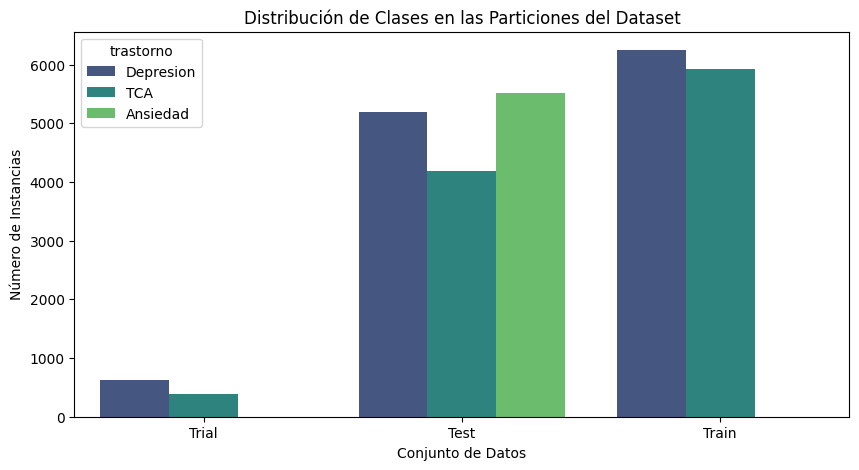

In [ ]:
# Conteo cruzado de particiones y trastornos
distribucion_clases = pd.crosstab(df_mental_risk['dataset_type'], df_mental_risk['trastorno'], margins=True)
print("=== Distribución de instancias por Conjunto y Trastorno ===")
display(distribucion_clases)

# Visualización del desbalanceo
plt.figure(figsize=(10, 5))
sns.countplot(data=df_mental_risk, x='dataset_type', hue='trastorno', palette='viridis')
plt.title('Distribución de Clases en las Particiones del Dataset')
plt.ylabel('Número de Instancias')
plt.xlabel('Conjunto de Datos')
plt.show()

## 1.3 Calidad del Dato: Valores Nulos e Instancias Repetidas
Para garantizar que el algoritmo DBSCAN calcule correctamente las vecindades (Epsilon) y los puntos centrales (MinPts), es imperativo evaluar la presencia de valores atípicos y ruidos absolutos como los valores nulos o los mensajes exactamente duplicados (que generan zonas de densidad infinita, es decir, distancia euclídea = 0).

In [ ]:
# 1. Valores Nulos (Missing Values)
missing_messages = df_mental_risk['message'].replace('nan', np.nan).isnull().sum()
print(f"Mensajes nulos o vacíos: {missing_messages}")

# 2. Instancias Repetidas (Duplicados exactos)
# Se ignoran duplicados lícitos como los id_message, nos centramos en el contenido textual
duplicated_messages = df_mental_risk.duplicated(subset=['message']).sum()
print(f"Mensajes exactamente duplicados en el corpus: {duplicated_messages}")

# Mostramos algunos ejemplos de los mensajes duplicados más comunes
if duplicated_messages > 0:
    print("\nEjemplos de mensajes más repetidos:")
    display(df_mental_risk['message'].value_counts().head(5))

Mensajes nulos o vacíos: 0
Mensajes exactamente duplicados en el corpus: 31

Ejemplos de mensajes más repetidos:


,count
message,
Muchas gracias por los consejos,3
cara con ceja alzada cara con ceja alzada,3
Que tal lo llevan,2
dorso de mano con índice hacia arriba dorso de mano con índice hacia arriba,2
manos aplaudiendo tono de piel claro,2


## 1.4 Rango de Atributos: Longitud del Texto
Analizamos el rango de la variable principal (`message`). Dado que el texto se convertirá en un vector numérico, la longitud del mensaje original influye en su representación (especialmente en aproximaciones dispersas como BoW/TF-IDF, donde textos cortos generan vectores extremadamente esparsos).

=== Estadísticas Descriptivas de la Longitud de Mensajes (Palabras) ===


,word_count
count,28085.000000
mean,14.699056
std,26.378062
min,1.000000
25%,6.000000
50%,9.000000
75%,16.000000
max,899.000000



=== Instancias con un número exacto de palabras (Primeras 20 longitudes) ===


,Número de Palabras,Cantidad de Instancias (Mensajes)
0,1,7
1,2,33
2,3,82
3,4,2437
4,5,2986
5,6,2836
6,7,2393
7,8,2078
8,9,1786
9,10,1464


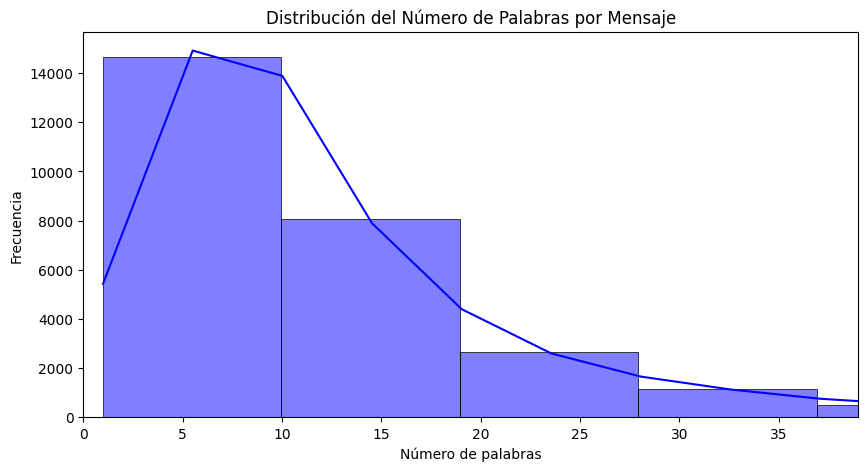

In [ ]:
# Calcular el número de palabras por mensaje
df_mental_risk['word_count'] = df_mental_risk['message'].apply(lambda x: len(str(x).split()))

print("=== Estadísticas Descriptivas de la Longitud de Mensajes (Palabras) ===")
display(df_mental_risk['word_count'].describe())

print("\n=== Instancias con un número exacto de palabras (Primeras 20 longitudes) ===")
# Contamos cuántos mensajes hay por cada longitud exacta de palabras y ordenamos (1, 2, 3...)
conteo_exacto = df_mental_risk['word_count'].value_counts().sort_index()

# Lo convertimos a DataFrame para una visualización más limpia en Jupyter/Colab
df_conteo = conteo_exacto.reset_index()
df_conteo.columns = ['Número de Palabras', 'Cantidad de Instancias (Mensajes)']
display(df_conteo.head(20)) # Muestra el desglose exacto de 1 a 20 palabras

# Visualizar la distribución del tamaño de los textos (rango de atributos)
plt.figure(figsize=(10, 5))
sns.histplot(df_mental_risk['word_count'], bins=100, kde=True, color='blue')
plt.title('Distribución del Número de Palabras por Mensaje')
plt.xlabel('Número de palabras')
plt.ylabel('Frecuencia')
plt.xlim(0, df_mental_risk['word_count'].quantile(0.95)) # Cortamos en el percentil 95 para la gráfica
plt.show()

In [ ]:
import re

# 1. Filtramos los mensajes de 3 palabras o menos
df_short = df_mental_risk[df_mental_risk['word_count'] <= 3].copy()

# 2. Función heurística para detectar emoticonos clásicos y descripciones de emojis
def is_emoticon_or_emoji(text):
    text = str(text).strip().lower()

    # Patrón para emoticonos clásicos de texto (ej. xD, :), :D, :v, <3, T_T, ^^, :/)
    text_emoticon_pattern = r'^([x:;=8]-?[)dpo3v\]\[)(/\|\\]|xd|<3|t_t|\^\^)$'
    if re.match(text_emoticon_pattern, text):
        return True

    # Palabras clave habituales en la transcripción de emojis del dataset
    emoji_keywords = ['cara', 'corazón', 'mano', 'dedo', 'sonrisa', 'ojos', 'pulgar']

    # Si el texto empieza por una de estas palabras, es altamente probable que sea un emoji descrito
    if any(text.startswith(kw) for kw in emoji_keywords):
        return True

    return False

# 3. Aplicamos la función para crear una nueva columna booleana
df_short['is_emoticon'] = df_short['message'].apply(is_emoticon_or_emoji)

# 4. Resultados cuantitativos
total_short = len(df_short)
total_emoticons = df_short['is_emoticon'].sum()

print("=== Análisis de Mensajes Cortos (<= 3 palabras) ===")
print(f"Total de mensajes cortos: {total_short}")
print(f"Mensajes clasificados como emoticonos/emojis: {total_emoticons}")
print(f"Representan el {(total_emoticons / total_short) * 100:.2f}% de los mensajes cortos.\n")

# 5. Exploración visual de los resultados
print("=== Top 10 Emoticonos/Emojis detectados ===")
display(df_short[df_short['is_emoticon']]['message'].value_counts().head(10))

print("\n=== Top 10 Mensajes cortos (No emoticonos) ===")
display(df_short[~df_short['is_emoticon']]['message'].value_counts().head(10))

=== Análisis de Mensajes Cortos (<= 3 palabras) ===
Total de mensajes cortos: 122
Mensajes clasificados como emoticonos/emojis: 34
Representan el 27.87% de los mensajes cortos.

=== Top 10 Emoticonos/Emojis detectados ===


,count
message,
mano abierta,2
cara estupefacta,2
mano saludando,2
cara llorando,2
cara llorando fuerte,2
cara sonrojada Bueno,1
ojos chispas,1
cara de payaso,1
cara sonriendo,1



=== Top 10 Mensajes cortos (No emoticonos) ===


,count
message,
No cara sonriente,1
Hola May chispas,1
Genial cara sonriente,1
Hey mano saludando,1
Adios corazón rojo,1
Igual cara sonriente,1
pierna,1
pie,1
Entiendo cara desanimada,1


## 1.5 Análisis de Vocabulario y Dispersión
Evaluamos la talla del vocabulario global para justificar la técnica de vectorización. Un vocabulario masivo con alta frecuencia de palabras únicas penaliza fuertemente a los algoritmos dispersos debido a la maldición de la dimensionalidad. Esto sustenta empíricamente la decisión de utilizar *embeddings* densos (como `sentence-transformers`) combinados con técnicas de reducción de dimensionalidad (PCA/t-SNE) antes de aplicar DBSCAN.

In [ ]:
# Unificamos todo el texto en minúsculas para extraer el vocabulario
all_text = " ".join(df_mental_risk['message'].tolist()).lower()

# Tokenización básica mediante expresiones regulares (separar por palabras alfanuméricas)
tokens = re.findall(r'\b\w+\b', all_text)

# Frecuencia de palabras
word_freq = Counter(tokens)
vocab_size = len(word_freq)

# Palabras que aparecen solo 1 vez (Out of Vocabulary potencial o hapax legomena)
hapax_legomena = sum(1 for word, freq in word_freq.items() if freq == 1)
ratio_hapax = (hapax_legomena / vocab_size) * 100

print(f"Total de palabras (tokens) en el corpus: {len(tokens)}")
print(f"Talla del vocabulario único: {vocab_size} palabras")
print(f"Palabras con frecuencia = 1 (potencial ruido/OOV): {hapax_legomena} ({ratio_hapax:.2f}% del vocabulario único)")

# Palabras más comunes (para ver si hace falta quitar stopwords)
print("\nTop 15 palabras más frecuentes (evidencia para limpieza de stopwords):")
for word, freq in word_freq.most_common(15):
    print(f"{word}: {freq}")

Total de palabras (tokens) en el corpus: 382124
Talla del vocabulario único: 26785 palabras
Palabras con frecuencia = 1 (potencial ruido/OOV): 14810 (55.29% del vocabulario único)

Top 15 palabras más frecuentes (evidencia para limpieza de stopwords):
de: 13924
que: 13846
y: 11039
no: 9024
la: 7651
a: 7545
me: 6966
es: 6196
en: 5820
el: 5506
lo: 5012
con: 4422
un: 3968
pero: 3905
si: 3802


# 2. PRUEBAS VECTORIZACION

In [ ]:
# Instalación de librerías necesarias
!pip install sentence-transformers pysentimiento
!python -m spacy download es_core_news_md

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer
from pysentimiento import create_analyzer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import re
import os

# Cargar el dataset (usando el corpus completo o una muestra, según vayas a experimentar)
# IMPORTANTE: Para guardar los vectores finales, asegúrate de procesar el DataFrame completo (df_mental_risk) o la partición que te interese (df_test).
try:
    # Usaremos una muestra para el ejemplo, cámbialo a df_mental_risk para la versión final
    df_experiment = df_mental_risk.sample(n=1000, random_state=42).copy()
except NameError:
    print("Por favor, asegúrate de tener cargado el dataset original en 'df_mental_risk'.")

df_experiment['text_raw'] = df_experiment['message'].astype(str)

# Limpieza básica para el baseline de TF-IDF
def clean_basic(text):
    return re.sub(r'[^a-z\á\é\í\ó\ú\ñ]+', ' ', str(text).lower())
df_experiment['text_clean'] = df_experiment['text_raw'].apply(clean_basic)

# Directorio para guardar los vectores localmente
output_dir = "vectorizaciones_guardadas"
os.makedirs(output_dir, exist_ok=True)

# Guardar los metadatos de los textos para alinearlos luego con los clusters
# Solo guardamos id, texto original y etiqueta para no ocupar espacio de más
df_metadata = df_experiment[['subject_id', 'id_message', 'trastorno', 'text_raw']]
df_metadata.to_csv(f"{output_dir}/metadata_textos.csv", index=False)
print("Metadatos guardados correctamente.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 9.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Metadatos guardados correctamente.


In [ ]:
# Variables para almacenar en memoria si se acaba de ejecutar
X_tfidf = None
X_static = None
X_contextual = None
X_emotion = None

# Función auxiliar para comprobar si el archivo ya existe
def get_or_create_embeddings(filename, df_col, generator_func, is_tfidf=False):
    filepath = f"{output_dir}/{filename}.npy"
    if os.path.exists(filepath):
        print(f"Cargando {filename} desde disco...")
        return np.load(filepath)
    else:
        print(f"Generando {filename}...")
        if is_tfidf:
            # TF-IDF requiere un tratamiento especial
            X = generator_func.fit_transform(df_col).toarray()
            # Opcionalmente puedes guardar el modelo tfidf con pickle si necesitas transformar nuevos datos
        else:
            # Para embeddings densos
            X = np.array([generator_func(t) for t in df_col])

        print(f"Guardando {filename} en disco...")
        np.save(filepath, X)
        return X

# 1. Baseline: TF-IDF (Texto Limpio)
tfidf = TfidfVectorizer(max_features=500)
X_tfidf = get_or_create_embeddings("X_tfidf_500d", df_experiment['text_clean'], tfidf, is_tfidf=True)

# 2. Estáticos: spaCy Word Embeddings
# Cargamos spaCy solo si vamos a generar los vectores
if not os.path.exists(f"{output_dir}/X_spacy_300d.npy"):
    nlp = spacy.load('es_core_news_md')
def get_spacy_vector(text):
    return nlp(str(text)).vector
X_static = get_or_create_embeddings("X_spacy_300d", df_experiment['text_raw'], get_spacy_vector)

# 3. Contextuales: Sentence Transformers
# Para sentence-transformers es más rápido pasarlo en lote que iterar con list comprehension
filepath_st = f"{output_dir}/X_contextual_384d.npy"
if os.path.exists(filepath_st):
    print("Cargando X_contextual_384d desde disco...")
    X_contextual = np.load(filepath_st)
else:
    print("Generando X_contextual_384d (Sentence-Transformers)...")
    model_st = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
    X_contextual = model_st.encode(df_experiment['text_raw'].tolist(), show_progress_bar=True)
    np.save(filepath_st, X_contextual)
    print("Guardado en disco.")

# 4. Emocionales: PySentimiento (RoBERTa)
if not os.path.exists(f"{output_dir}/X_emocional_7d.npy"):
    emotion_analyzer = create_analyzer(task="emotion", lang="es")
def get_emotion_vector(text):
    probas = emotion_analyzer.predict(str(text)).probas
    return list(probas.values())
X_emotion = get_or_create_embeddings("X_emocional_7d", df_experiment['text_raw'], get_emotion_vector)

print("Todas las vectorizaciones están listas (en memoria y guardadas localmente).")

Generando X_tfidf_500d...
Guardando X_tfidf_500d en disco...
Generando X_spacy_300d...
Guardando X_spacy_300d en disco...
Generando X_contextual_384d (Sentence-Transformers)...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Guardado en disco.


config.json:   0%|          | 0.00/1.08k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

Generando X_emocional_7d...
Guardando X_emocional_7d en disco...
Todas las vectorizaciones están listas (en memoria y guardadas localmente).


In [ ]:
# Si reinicias el notebook, puedes cargar los datos directamente así:
# X_tfidf = np.load(f"{output_dir}/X_tfidf_500d.npy")
# X_static = np.load(f"{output_dir}/X_spacy_300d.npy")
# X_contextual = np.load(f"{output_dir}/X_contextual_384d.npy")
# X_emotion = np.load(f"{output_dir}/X_emocional_7d.npy")

# Configuración del pipeline de pruebas
experiments = [
    {'name': 'TF-IDF (Baseline 500d -> PCA 50d)', 'X': X_tfidf, 'apply_pca': 50, 'eps': 0.5, 'min_samples': 5},
    {'name': 'Estáticos (spaCy 300d -> PCA 50d)', 'X': X_static, 'apply_pca': 50, 'eps': 2.0, 'min_samples': 5},
    {'name': 'Contextuales (Transformers 384d -> PCA 50d)', 'X': X_contextual, 'apply_pca': 50, 'eps': 1.5, 'min_samples': 5},
    # PySentimiento es directo, no necesita PCA
    {'name': 'Emocionales (PySentimiento 7d directos)', 'X': X_emotion, 'apply_pca': None, 'eps': 1.2, 'min_samples': 5}
]

results = []

for exp in experiments:
    # Verificación por si la celda se ejecuta sola y no están cargados en memoria
    if exp['X'] is None:
        print(f"Advertencia: Los vectores para {exp['name']} no están cargados. Sáltate este experimento o cárgalos con np.load()")
        continue

    X_current = exp['X']

    # Reducción PCA (solo si aplica)
    if exp['apply_pca']:
        pca = PCA(n_components=exp['apply_pca'], random_state=42)
        X_cluster = pca.fit_transform(X_current)
    else:
        X_cluster = X_current

    # Escalado (Fundamental antes de medir densidades con DBSCAN)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_cluster)

    # Inferencia DBSCAN (Sklearn)
    db = DBSCAN(eps=exp['eps'], min_samples=exp['min_samples'])
    labels = db.fit_predict(X_scaled)

    # Métricas
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    sil_score = -1
    if n_clusters > 1:
        try:
            sil_score = silhouette_score(X_scaled, labels)
        except:
            pass

    results.append({
        'Vectorización': exp['name'],
        'Dimensiones para DBSCAN': X_scaled.shape[1],
        'Num Clusters Encontrados': n_clusters,
        'Mensajes como Ruido (-1)': n_noise,
        'Silhouette Score': round(sil_score, 4)
    })

# Visualización comparativa
df_results = pd.DataFrame(results)
display(df_results.sort_values(by='Silhouette Score', ascending=False))

,Vectorización,Dimensiones para DBSCAN,Num Clusters Encontrados,Mensajes como Ruido (-1),Silhouette Score
3,Emocionales (PySentimiento 7d directos),7,5,55,0.5611
0,TF-IDF (Baseline 500d -> PCA 50d),50,1,992,-1.0000
1,Estáticos (spaCy 300d -> PCA 50d),50,0,1000,-1.0000
2,Contextuales (Transformers 384d -> PCA 50d),50,0,1000,-1.0000
